In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score,ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler

In [2]:
df=pd.read_csv("Social_Network_Ads.csv")
df['Gender']=df['Gender'].map({'Male':0,'Female':1})
df=df.drop(columns='User ID')

In [3]:
x=df.drop('Purchased',axis=1)
y=df['Purchased']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.25,random_state=42)

In [4]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)
model = LogisticRegression()
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
print(accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.88
[[61  2]
 [10 27]]
              precision    recall  f1-score   support

           0       0.86      0.97      0.91        63
           1       0.93      0.73      0.82        37

    accuracy                           0.88       100
   macro avg       0.90      0.85      0.86       100
weighted avg       0.89      0.88      0.88       100



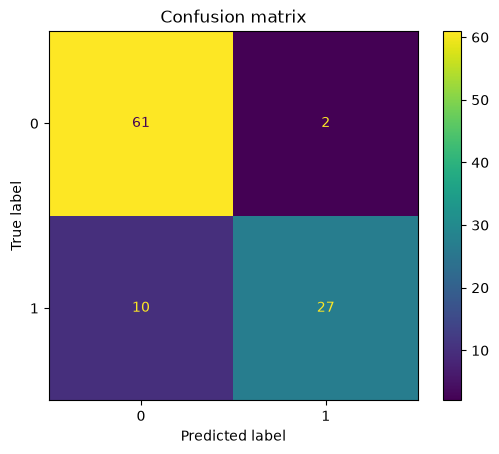

In [6]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred)
plt.title("Confusion matrix")
plt.show()